# Task 2 — Neural CTR Prediction

This notebook uses the supplied **binary CTR dataset** described in the task: 13 numerical fields, 26 categorical fields, and a binary `label`.

### Experimental rules
- The training file is split once into train/validation with `random_state=42` and stratification.
- Test is never used for architecture selection or preprocessing fitting.
- Numeric imputation/scaling and categorical vocabularies are fit **only on the training portion**.
- Categorical fields are integer-encoded into learned embeddings, then concatenated with the normalized numeric fields. The result goes through an ordinary TensorFlow/Keras MLP; there is **no explicit interaction module** in this baseline.
- Several small MLP architectures are compared on validation log loss.
- The threshold for the reported F1 score is selected on validation data and then applied once to the untouched test set.


In [1]:
from pathlib import Path
import csv
import math
import os
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    log_loss, f1_score, precision_recall_curve,
)
from sklearn.calibration import calibration_curve

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

GPU_DEVICES = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("Available GPU devices:", GPU_DEVICES)
if GPU_DEVICES:
    print("TensorFlow will use the available GPU backend automatically.")
else:
    print("No TensorFlow GPU device detected; running on CPU.")


Device: mps


In [2]:
def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "datasets").exists():
            return p
    raise FileNotFoundError("Could not find the repository root containing a datasets/ folder.")


REPO_ROOT = find_repo_root()
DATASETS_DIR = REPO_ROOT / "datasets"
CACHE_DIR = REPO_ROOT / ".cache" / "ctr_task_data"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

ARCHIVE = DATASETS_DIR / "dataset (tasks 2 and 3).zip"
if not ARCHIVE.exists():
    raise FileNotFoundError(f"Expected supplied dataset at: {ARCHIVE}")

EXTRACT_DIR = CACHE_DIR / "extracted"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ARCHIVE) as zf:
    zf.extractall(EXTRACT_DIR)

files = [p for p in EXTRACT_DIR.rglob("*") if p.is_file()]
train_candidates = [p for p in files if "train" in p.name.lower() and p.suffix.lower() in {".csv", ".txt", ".tsv", ".data"}]
test_candidates = [p for p in files if "test" in p.name.lower() and p.suffix.lower() in {".csv", ".txt", ".tsv", ".data"}]

print("Train candidates:", train_candidates)
print("Test candidates:", test_candidates)
if not train_candidates or not test_candidates:
    raise FileNotFoundError("Could not automatically find train/test files inside the supplied zip.")

TRAIN_FILE = train_candidates[0]
TEST_FILE = test_candidates[0]


def detect_separator(path):
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        sample = f.read(8192)
    if "\t" in sample:
        return "\t"
    if "," in sample:
        return ","
    if ";" in sample:
        return ";"
    return None


def has_header(path, sep):
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        line = f.readline().strip()
    parts = line.split(sep) if sep else line.split()
    normalized = {p.strip().strip('"').lower() for p in parts}
    return "label" in normalized or any(x.startswith("c1") for x in normalized) or any(x.startswith("i1") for x in normalized)


def load_ctr_file(path):
    sep = detect_separator(path)
    header = 0 if has_header(path, sep or " ") else None
    df = pd.read_csv(path, sep=sep, header=header, engine="python")
    if header is None:
        n_cols = df.shape[1]
        if n_cols == 40:
            df.columns = ["label"] + [f"I{i}" for i in range(1,14)] + [f"C{i}" for i in range(1,27)]
        else:
            raise ValueError(
                f"Headerless file {path.name} has {n_cols} columns. "
                "Expected 40 columns = label + 13 numeric + 26 categorical. "
                "Check the supplied task README's exact column order."
            )
    else:
        df.columns = [str(c).strip() for c in df.columns]
    return df


train_raw = load_ctr_file(TRAIN_FILE)
test_raw = load_ctr_file(TEST_FILE)

print("Train shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
print("Train columns:", list(train_raw.columns))
print(train_raw.head(3))


Train candidates: [PosixPath('/Users/anirbankumarsil/Documents/AnirbanKumarSil-Intelligence-SIG-Recs-2026/mandatory-tasks/recommender-systems-cf-to-dlrm/.cache/ctr_task_data/extracted/train.csv')]
Test candidates: [PosixPath('/Users/anirbankumarsil/Documents/AnirbanKumarSil-Intelligence-SIG-Recs-2026/mandatory-tasks/recommender-systems-cf-to-dlrm/.cache/ctr_task_data/extracted/test.csv')]
Train shape: (40000, 40)
Test shape: (10000, 40)
Train columns: ['label', 'integer_feature_1', 'integer_feature_2', 'integer_feature_3', 'integer_feature_4', 'integer_feature_5', 'integer_feature_6', 'integer_feature_7', 'integer_feature_8', 'integer_feature_9', 'integer_feature_10', 'integer_feature_11', 'integer_feature_12', 'integer_feature_13', 'categorical_feature_1', 'categorical_feature_2', 'categorical_feature_3', 'categorical_feature_4', 'categorical_feature_5', 'categorical_feature_6', 'categorical_feature_7', 'categorical_feature_8', 'categorical_feature_9', 'categorical_feature_10', 'categ

In [3]:
# Identify the 13 dense integer features, 26 categorical features, and label.

def find_label_column(df):
    for c in df.columns:
        if str(c).strip().lower() == "label":
            return c
    # Headerless Criteo-style data uses the first column as the label.
    if df.shape[1] == 40:
        return df.columns[0]
    raise ValueError("Could not identify the label column.")


def split_feature_columns(train_df, test_df):
    label_col = find_label_column(train_df)
    candidates = [c for c in train_df.columns if c != label_col]
    numeric = [c for c in candidates if str(c).lower().startswith("i") and str(c)[1:].isdigit()]
    categorical = [c for c in candidates if str(c).lower().startswith("c") and str(c)[1:].isdigit()]

    if len(numeric) != 13 or len(categorical) != 26:
        # Fallback based on position for exactly 40-column files.
        if train_df.shape[1] == 40 and label_col == train_df.columns[0]:
            numeric = list(train_df.columns[1:14])
            categorical = list(train_df.columns[14:40])
        else:
            raise ValueError(
                f"Expected 13 numeric + 26 categorical fields, got {len(numeric)} numeric + {len(categorical)} categorical. "
                "Inspect train_raw.columns and adapt this cell to the exact supplied schema."
            )
    return label_col, numeric, categorical


LABEL_COL, NUM_COLS, CAT_COLS = split_feature_columns(train_raw, test_raw)
if LABEL_COL not in test_raw.columns and test_raw.shape[1] == train_raw.shape[1] - 1:
    raise ValueError(
        "The supplied test file has no label column, so ROC-AUC/PR-AUC/log-loss/accuracy/F1 cannot be computed on test. "
        "The recruitment task requires these metrics, so use the labeled test file specified by the task dataset."
    )

train_y = pd.to_numeric(train_raw[LABEL_COL], errors="coerce").astype(np.int64)
if not set(train_y.dropna().unique()).issubset({0,1}):
    raise ValueError("The label must be binary 0/1.")

# We choose the validation split once and reuse exactly the same indices in Tasks 2 and 3.
indices = np.arange(len(train_raw))
train_idx, val_idx = train_test_split(
    indices, test_size=0.10, random_state=SEED, stratify=train_y.to_numpy()
)

train_part = train_raw.iloc[train_idx].copy()
val_part = train_raw.iloc[val_idx].copy()

# ----- Fit preprocessing ONLY on train_part -----
num_medians = {}
num_means = {}
num_stds = {}
cat_maps = {}
cat_vocab_sizes = []

for c in NUM_COLS:
    x = pd.to_numeric(train_part[c], errors="coerce")
    median = float(x.median())
    x_filled = x.fillna(median).astype(np.float32)
    mean = float(x_filled.mean())
    std = float(x_filled.std())
    if std < 1e-8:
        std = 1.0
    num_medians[c] = median
    num_means[c] = mean
    num_stds[c] = std

for c in CAT_COLS:
    values = train_part[c].astype("string").fillna("<NA>")
    uniques = pd.Index(values.unique())
    # 0 is reserved for unknown validation/test categories.
    mapping = {value: idx + 1 for idx, value in enumerate(uniques)}
    cat_maps[c] = mapping
    cat_vocab_sizes.append(len(mapping) + 1)


def transform_frame(df, include_label=True):
    x_num = np.zeros((len(df), len(NUM_COLS)), dtype=np.float32)
    x_cat = np.zeros((len(df), len(CAT_COLS)), dtype=np.int64)

    for j, c in enumerate(NUM_COLS):
        x = pd.to_numeric(df[c], errors="coerce").fillna(num_medians[c]).astype(np.float32)
        x_num[:, j] = ((x - num_means[c]) / num_stds[c]).to_numpy()

    for j, c in enumerate(CAT_COLS):
        values = df[c].astype("string").fillna("<NA>")
        x_cat[:, j] = values.map(cat_maps[c]).fillna(0).astype(np.int64).to_numpy()

    if include_label:
        y = pd.to_numeric(df[LABEL_COL], errors="coerce").astype(np.float32).to_numpy()
        return x_num, x_cat, y
    return x_num, x_cat


X_num_train, X_cat_train, y_train = transform_frame(train_part, True)
X_num_val, X_cat_val, y_val = transform_frame(val_part, True)
X_num_test, X_cat_test, y_test = transform_frame(test_raw, True)

print("Numeric shape:", X_num_train.shape)
print("Categorical shape:", X_cat_train.shape)
print("Vocabulary sizes (first 5):", cat_vocab_sizes[:5])
print("Positive rate train/val/test:", y_train.mean(), y_val.mean(), y_test.mean())


Numeric shape: (36000, 13)
Categorical shape: (36000, 26)
Vocabulary sizes (first 5): [12021, 3552, 4790, 1736, 3975]
Positive rate train/val/test: 0.032 0.032 0.0335


In [4]:
BATCH_SIZE = 2048

def make_model_inputs(x_num, x_cat):
    """Convert numeric/categorical NumPy arrays into Keras model inputs."""
    inputs = {"numeric": x_num.astype(np.float32)}
    for j in range(x_cat.shape[1]):
        inputs[f"cat_{j}"] = x_cat[:, j].astype(np.int32)
    return inputs


train_inputs = make_model_inputs(X_num_train, X_cat_train)
val_inputs = make_model_inputs(X_num_val, X_cat_val)
test_inputs = make_model_inputs(X_num_test, X_cat_test)


def make_dataset(inputs, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((inputs, y.astype(np.float32)))
    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(y), 100_000),
            seed=SEED,
            reshuffle_each_iteration=True,
        )
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_inputs, y_train, shuffle=True)
val_ds = make_dataset(val_inputs, y_val, shuffle=False)
test_ds = make_dataset(test_inputs, y_test, shuffle=False)


def best_f1_threshold(y_true, prob):
    precision, recall, thresholds = precision_recall_curve(y_true, prob)
    if len(thresholds) == 0:
        return 0.5, f1_score(y_true, (prob >= 0.5).astype(int), zero_division=0)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    idx = int(np.nanargmax(f1))
    return float(thresholds[idx]), float(f1[idx])


def evaluate_binary(y_true, logits, threshold=0.5):
    prob = 1.0 / (1.0 + np.exp(-np.clip(logits, -50, 50)))
    pred = (prob >= threshold).astype(np.int64)
    return {
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "LogLoss": log_loss(y_true, prob, labels=[0, 1]),
        "Accuracy": accuracy_score(y_true, pred),
        "F1": f1_score(y_true, pred, zero_division=0),
    }, prob


def collect_logits(model, inputs, batch_size=BATCH_SIZE):
    """Run inference and return labels and raw logits."""
    logits = model.predict(inputs, batch_size=batch_size, verbose=0).reshape(-1)
    y = inputs["_y"] if "_y" in inputs else None
    return logits


def collect_logits_and_labels(model, inputs, y, batch_size=BATCH_SIZE):
    logits = model.predict(inputs, batch_size=batch_size, verbose=0).reshape(-1)
    return y.astype(np.float32), logits


def train_model(model, train_ds, val_ds, epochs=8, lr=1e-3, patience=2):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
        metrics=[],
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=patience,
        min_delta=1e-5,
        restore_best_weights=True,
        verbose=1,
    )

    start = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=[early_stopping],
        verbose=1,
    )
    elapsed = time.perf_counter() - start

    hist = pd.DataFrame({
        "epoch": np.arange(1, len(history.history["loss"]) + 1),
        "train_loss": history.history["loss"],
        "val_logloss": history.history["val_loss"],
    })

    # Compute validation ROC-AUC once per recorded epoch from history is not available
    # directly, so it will be evaluated after training for model selection.
    hist["val_roc_auc"] = np.nan
    hist["seconds"] = elapsed / len(hist)

    return model, hist, elapsed


def count_parameters(model):
    return int(model.count_params())


def parameter_memory_mib(model, bytes_per_param=4):
    return count_parameters(model) * bytes_per_param / (1024 ** 2)


## Vanilla neural model

The model has one TensorFlow/Keras embedding table per categorical field. Their vectors are concatenated with the 13 standardized dense features and passed into an MLP. This gives us a clean baseline before introducing DLRM-style pairwise interactions.


In [5]:
class VanillaCTR(tf.keras.Model):
    def __init__(self, vocab_sizes, embedding_dim=8, hidden_dims=(128, 64), dropout=0.1):
        super().__init__()

        self.numeric_input = tf.keras.Input(
            shape=(13,), dtype=tf.float32, name="numeric"
        )

        self.category_inputs = [
            tf.keras.Input(shape=(), dtype=tf.int32, name=f"cat_{j}")
            for j in range(26)
        ]

        self.embeddings = [
            tf.keras.layers.Embedding(
                input_dim=vocab_size,
                output_dim=embedding_dim,
                name=f"embedding_{j}",
            )
            for j, vocab_size in enumerate(vocab_sizes)
        ]

        self.hidden_layers = []
        for h in hidden_dims:
            self.hidden_layers.append(tf.keras.layers.Dense(h, activation="relu"))
            self.hidden_layers.append(tf.keras.layers.Dropout(dropout))

        self.output_layer = tf.keras.layers.Dense(1, name="logit")

    def call(self, inputs, training=False):
        x_num = inputs["numeric"]

        cat_vectors = [
            embedding(inputs[f"cat_{j}"])
            for j, embedding in enumerate(self.embeddings)
        ]

        x = tf.concat([x_num] + cat_vectors, axis=1)

        for layer in self.hidden_layers:
            x = layer(x, training=training)

        return self.output_layer(x)


In [6]:
ARCHITECTURES = {
    "small": (128, 64),
    "medium": (256, 128),
    "deep": (256, 128, 64),
}

architecture_rows = []
trained_models = {}
histories = {}

for name, hidden_dims in ARCHITECTURES.items():
    print("\n===", name, hidden_dims, "===")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = VanillaCTR(
        cat_vocab_sizes,
        embedding_dim=8,
        hidden_dims=hidden_dims,
        dropout=0.10,
    )

    # Build the model once so count_params() is available.
    _ = model(train_inputs, training=False)

    model, history, train_seconds = train_model(
        model,
        train_ds,
        val_ds,
        epochs=8,
        lr=1e-3,
        patience=2,
    )

    yv, val_logits = collect_logits_and_labels(model, val_inputs, y_val)
    val_prob = 1 / (1 + np.exp(-np.clip(val_logits, -50, 50)))
    val_threshold, val_f1 = best_f1_threshold(yv, val_prob)
    val_metrics, _ = evaluate_binary(yv, val_logits, threshold=val_threshold)

    architecture_rows.append({
        "Architecture": name,
        "Hidden dims": str(hidden_dims),
        "Params": count_parameters(model),
        "Param memory (MiB)": parameter_memory_mib(model),
        "Val ROC-AUC": val_metrics["ROC-AUC"],
        "Val PR-AUC": val_metrics["PR-AUC"],
        "Val LogLoss": val_metrics["LogLoss"],
        "Val F1": val_metrics["F1"],
        "Val threshold": val_threshold,
        "Train seconds": train_seconds,
    })

    trained_models[name] = model
    histories[name] = history

architecture_results = pd.DataFrame(architecture_rows).sort_values("Val LogLoss")
architecture_results



=== small (128, 64) ===
Epoch 01 | train BCE=0.38808 | val logloss=0.15575 | val ROC-AUC=0.56546 | 1.1s
Epoch 02 | train BCE=0.16625 | val logloss=0.14947 | val ROC-AUC=0.58805 | 0.2s
Epoch 03 | train BCE=0.14568 | val logloss=0.14219 | val ROC-AUC=0.61154 | 0.2s
Epoch 04 | train BCE=0.13866 | val logloss=0.13942 | val ROC-AUC=0.62448 | 0.1s
Epoch 05 | train BCE=0.13643 | val logloss=0.13851 | val ROC-AUC=0.63585 | 0.2s
Epoch 06 | train BCE=0.13410 | val logloss=0.13794 | val ROC-AUC=0.64332 | 0.2s
Epoch 07 | train BCE=0.13143 | val logloss=0.13807 | val ROC-AUC=0.64774 | 0.2s
Epoch 08 | train BCE=0.12964 | val logloss=0.13791 | val ROC-AUC=0.65124 | 0.1s

=== medium (256, 128) ===
Epoch 01 | train BCE=0.31012 | val logloss=0.17105 | val ROC-AUC=0.57702 | 0.4s
Epoch 02 | train BCE=0.15756 | val logloss=0.14223 | val ROC-AUC=0.62330 | 0.2s
Epoch 03 | train BCE=0.13829 | val logloss=0.13762 | val ROC-AUC=0.64586 | 0.2s
Epoch 04 | train BCE=0.13371 | val logloss=0.13730 | val ROC-AUC=0.6

,Architecture,Hidden dims,Params,Param memory (MiB),Val ROC-AUC,Val PR-AUC,Val LogLoss,Val F1,Val threshold,Train seconds
1,medium,"(256, 128)",861385,3.285923,0.658952,0.067943,0.137048,0.123007,0.057475,1.408421
2,deep,"(256, 128, 64)",869577,3.317173,0.650058,0.064427,0.137562,0.123853,0.073081,1.224485
0,small,"(128, 64)",808265,3.083286,0.651244,0.064063,0.137908,0.121212,0.063173,3.774485


In [7]:
# Select architecture using validation ONLY. Lower validation log loss is the selection rule.
best_name = architecture_results.iloc[0]["Architecture"]
best_model = trained_models[best_name]
print("Selected architecture:", best_name)


Selected architecture: medium


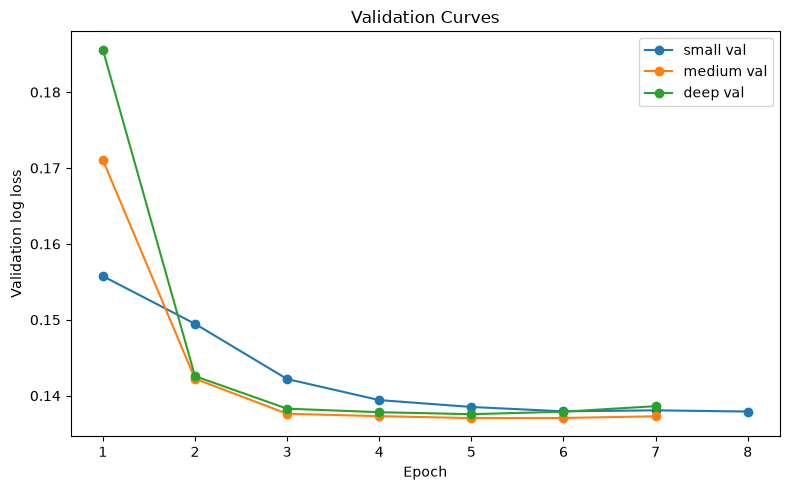

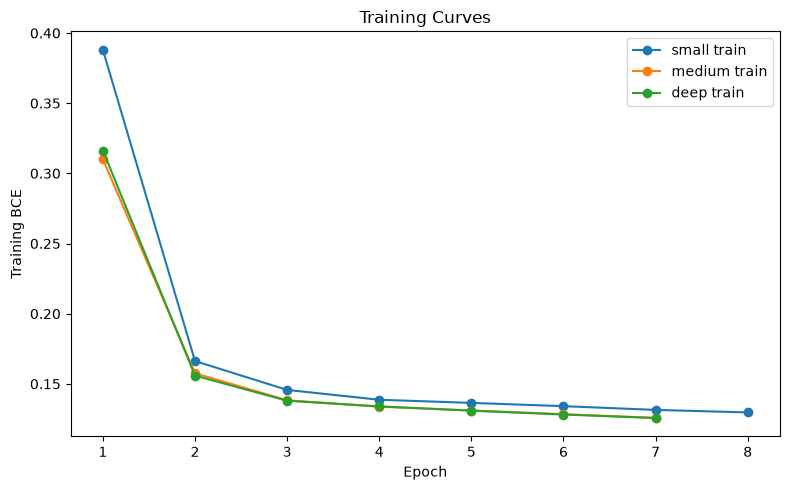

In [8]:
# Training / validation curves for every architecture.
plt.figure(figsize=(8, 5))
for name, hist in histories.items():
    plt.plot(
        hist["epoch"],
        hist["val_logloss"],
        marker="o",
        label=f"{name} validation",
    )
plt.xlabel("Epoch")
plt.ylabel("Validation log loss")
plt.title("Validation Curves")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for name, hist in histories.items():
    plt.plot(
        hist["epoch"],
        hist["train_loss"],
        marker="o",
        label=f"{name} training",
    )
plt.xlabel("Epoch")
plt.ylabel("Training binary cross-entropy")
plt.title("Training Curves")
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
# Final test evaluation — threshold was selected on validation, not test.
yv, val_logits = collect_logits_and_labels(best_model, val_inputs, y_val)
val_prob = 1 / (1 + np.exp(-np.clip(val_logits, -50, 50)))
selected_threshold, _ = best_f1_threshold(yv, val_prob)

yt, test_logits = collect_logits_and_labels(best_model, test_inputs, y_test)
test_metrics, test_prob = evaluate_binary(
    yt,
    test_logits,
    threshold=selected_threshold,
)

print("Validation-selected F1 threshold:", selected_threshold)
print(pd.Series(test_metrics))


Validation-selected F1 threshold: 0.05747503787279129
ROC-AUC     0.660679
PR-AUC      0.065421
LogLoss     0.142355
Accuracy    0.896900
F1          0.101133
dtype: float64


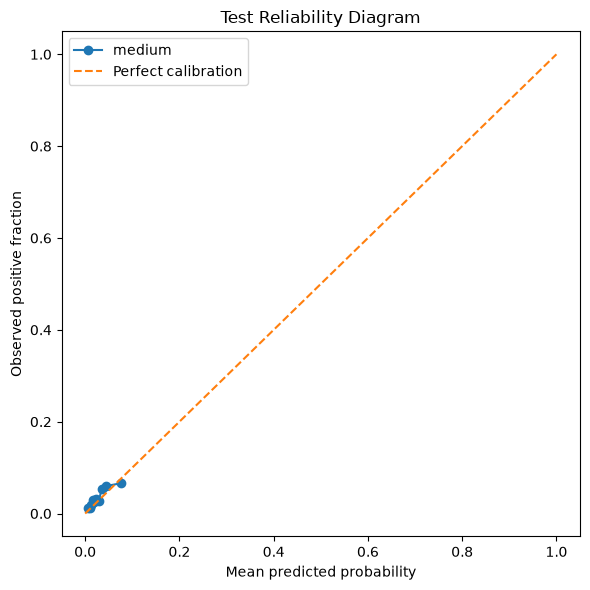

In [10]:
# Reliability / calibration plot.
frac_pos, mean_pred = calibration_curve(yt, test_prob, n_bins=10, strategy="quantile")

plt.figure(figsize=(6, 6))
plt.plot(mean_pred, frac_pos, marker="o", label=best_name)
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("Test Reliability Diagram")
plt.legend()
plt.tight_layout()
plt.show()


In [11]:
# Compact submission table.
final_task2 = pd.DataFrame([{
    "Model": f"Vanilla NN ({best_name})",
    **test_metrics,
    "F1 threshold": selected_threshold,
    "Parameters": count_parameters(best_model),
    "Parameter memory (MiB)": parameter_memory_mib(best_model),
}])
final_task2


,Model,ROC-AUC,PR-AUC,LogLoss,Accuracy,F1,F1 threshold,Parameters,Parameter memory (MiB)
0,Vanilla NN (medium),0.660679,0.065421,0.142355,0.8969,0.101133,0.057475,861385,3.285923


## What to discuss in the report

1. Explain why train-only preprocessing matters: using validation/test categories or statistics to build encoders can leak information across the evaluation boundary.
2. Compare the architectures using validation results, then quote exactly one final test row for the selected model.
3. Discuss the train/validation curves: widening loss gaps or validation degradation are evidence of overfitting.
4. Explain that the vanilla network can learn nonlinear combinations through the MLP, but it does not impose an explicit low-dimensional pairwise interaction operator like DLRM.
5. Do not invent numbers before the notebook is run on the supplied dataset.
